In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas
import scipy

In [4]:
df = pandas.read_csv("../../results/ancestry/DGRP_ancestry.tsv", sep="\\s+")
arr = np.array(df)[:, 2:].astype(int)
p_afr = np.sum(arr == 1, axis=1) / np.sum(arr >= 0, axis=1)
chroms = list(df["chrom"])
positions = np.array(df["position"])

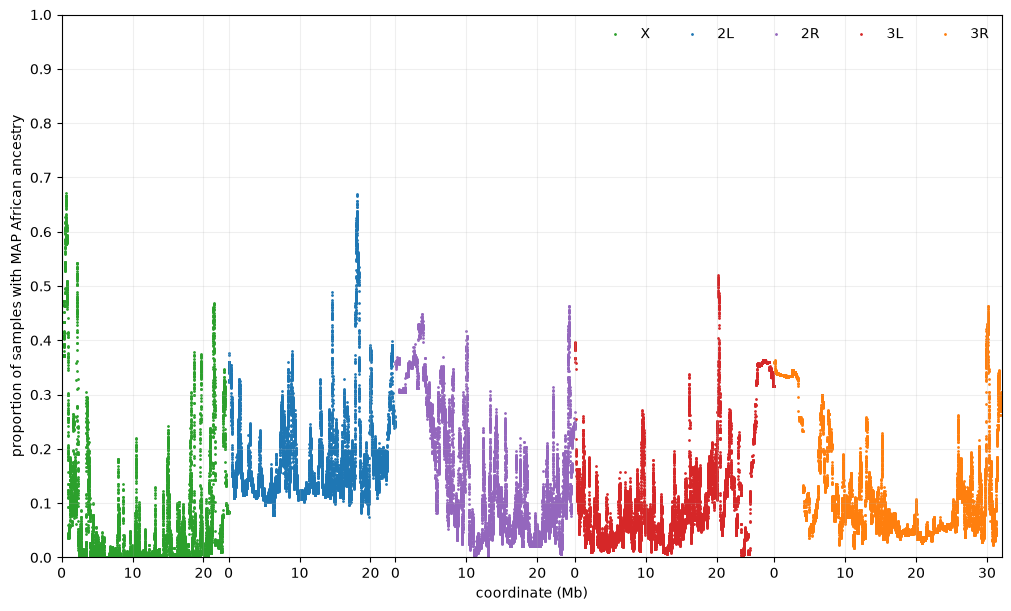

In [7]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6), layout="constrained")

colors = ["tab:green", "tab:blue", "tab:purple", "tab:red", "tab:orange"]
split_points = [0]
xticks = []
xtick_labels = []
for i, chrom in enumerate(["X", "2L", "2R", "3L", "3R"]):
    mask = np.array([c == chrom for c in chroms])
    xs = positions[mask] + split_points[-1]
    ys = p_afr[mask]
    plt.scatter(xs, ys, s=1, color=colors[i], label=chrom)
    _xticks = np.arange(0, positions[mask][-1], 10_000_000)
    xtick_labels += list(_xticks)
    xticks += list(_xticks + split_points[-1])
    split_points.append(xs[-1])

ax.legend(framealpha=0, ncols=5)
ax.set_ylim(0, 1)
ax.set_xlim(0, split_points[-1])
ax.grid(alpha=0.2)
# xticks = np.arange(0, 140_000_000, 10_000_000)
ax.set_xticks(xticks, (np.array(xtick_labels) / 1e6).astype(int))
ax.set_xlabel("coordinate (Mb)")
ax.set_yticks(np.linspace(0, 1, 11))
ax.set_ylabel("proportion of samples with MAP African ancestry")
plt.savefig("../../figures/African_ancestry_landscape_v3.png")

In [6]:
def count_types(locusA, locusB):
    chromA, (startA, stopA) = locusA
    chromB, (startB, stopB) = locusB
    dfA = df[
        (df["chrom"] == chromA)
        & (df["position"] >= startA) 
        & (df["position"] <= stopA)]
    dfB = df[
        (df["chrom"] == chromB)
        & (df["position"] >= startB) 
        & (df["position"] <= stopB)]
    samples = list(df.columns[2:])
    comparisons = []
    type_counts = []
    p_fets = []
    for i, rowA in dfA.iterrows():
        for j, rowB in dfB.iterrows():
            siteA = f"{rowA['chrom']}:{rowA['position']}"
            siteB = f"{rowB['chrom']}:{rowB['position']}"
            comparisons.append((siteA, siteB))
            AA, AE, EA, EE = 0, 0, 0, 0
            for sample in samples:
                ancA = rowA[sample]
                ancB = rowB[sample]
                if ancA == 1 and ancB == 1:
                    AA += 1
                elif ancA == 1 and ancB == 0:
                    AE += 1
                elif ancA == 0 and ancB == 1:
                    EA += 1
                elif ancA == 0 and ancB == 0:
                    EE += 1
            type_counts_ij = [AA, AE, EA, EE]
            type_counts.append(type_counts_ij)
            table = np.reshape(type_counts_ij, (2, 2))
            p_fet = scipy.stats.fisher_exact(table, alternative="greater").pvalue
            p_fets.append(p_fet)
    for comp, counts, p_fet, in zip(comparisons, type_counts, p_fets):
        print(comp, counts, sum(counts), p_fet)
    
    return comparisons, type_counts

In [7]:
# Build 5: X:20,815,287..20,820,196 x 3L:4,416,058..4,419,369
# Build 6: X:20,944,260..20,949,169 x 3L:4,416,058..4,419,369
ret = count_types(
    ("X", (20_944_260, 20_949_169)),
    ("3L", (4_416_058, 4_419_369)),
)

('X:20944322', '3L:4416670') [0, 20, 31, 1032] 1083 1.0
('X:20944322', '3L:4417719') [0, 20, 33, 1026] 1079 1.0
('X:20944322', '3L:4418721') [0, 20, 34, 1028] 1082 1.0
('X:20945359', '3L:4416670') [0, 20, 31, 1032] 1083 1.0
('X:20945359', '3L:4417719') [0, 20, 33, 1026] 1079 1.0
('X:20945359', '3L:4418721') [0, 20, 34, 1028] 1082 1.0
('X:20946426', '3L:4416670') [0, 20, 31, 1032] 1083 1.0
('X:20946426', '3L:4417719') [0, 20, 33, 1026] 1079 1.0
('X:20946426', '3L:4418721') [0, 20, 34, 1028] 1082 1.0
('X:20947514', '3L:4416670') [0, 24, 31, 1030] 1085 1.0
('X:20947514', '3L:4417719') [0, 24, 33, 1024] 1081 1.0
('X:20947514', '3L:4418721') [0, 24, 33, 1026] 1083 1.0
('X:20948754', '3L:4416670') [0, 20, 31, 1040] 1091 1.0
('X:20948754', '3L:4417719') [0, 20, 33, 1034] 1087 1.0
('X:20948754', '3L:4418721') [0, 20, 34, 1036] 1090 1.0


In [16]:
# Build 5: 2R:11,353,691..11,359,516 x 3L:11,079,088..11,085,304
# Build 6: 2R:15,466,186..15,472,011 x 3L:11,085,988..11,092,204

ret = count_types(
    ("2R", (15_466_186, 15_472_011)),
    ("3L", (11_085_988, 11_092_204)),
)

('2R:15466362', '3L:11086797') [67, 208, 99, 572] 946 0.0003876472703485642
('2R:15466362', '3L:11088869') [73, 205, 108, 562] 948 0.00027470077109579156
('2R:15466362', '3L:11090061') [70, 207, 107, 563] 947 0.000718030309415552
('2R:15466362', '3L:11091469') [61, 211, 95, 575] 942 0.0016909719054786234
('2R:15467604', '3L:11086797') [69, 208, 97, 569] 943 0.00014571342759533079
('2R:15467604', '3L:11088869') [75, 205, 106, 558] 944 0.00011226969850022244
('2R:15467604', '3L:11090061') [72, 207, 105, 559] 943 0.0003053039808009359
('2R:15467604', '3L:11091469') [63, 211, 93, 571] 938 0.0006959223294205808
('2R:15468752', '3L:11086797') [67, 202, 98, 573] 940 0.00017650271252622442
('2R:15468752', '3L:11088869') [73, 199, 107, 562] 941 0.00012515069610242218
('2R:15468752', '3L:11090061') [70, 201, 106, 563] 940 0.000347459504256168
('2R:15468752', '3L:11091469') [61, 205, 94, 575] 935 0.0008789627512487645
('2R:15469835', '3L:11086797') [68, 211, 97, 574] 950 0.00023038669861619973
('

In [15]:
ret = count_types(
    ("X", (2_000_000, 2_005_000)),
    ("X", (18_500_000, 18_505_000)),
)

('X:2001327', 'X:18500092') [0, 103, 2, 1103] 1208 1.0
('X:2001327', 'X:18501093') [0, 103, 2, 1103] 1208 1.0
('X:2001327', 'X:18502346') [0, 103, 2, 1103] 1208 1.0
('X:2001327', 'X:18503605') [0, 103, 2, 1103] 1208 1.0
('X:2002361', 'X:18500092') [0, 99, 2, 1108] 1209 1.0
('X:2002361', 'X:18501093') [0, 99, 2, 1108] 1209 1.0
('X:2002361', 'X:18502346') [0, 99, 2, 1108] 1209 1.0
('X:2002361', 'X:18503605') [0, 99, 2, 1108] 1209 1.0
('X:2003573', 'X:18500092') [0, 111, 2, 1096] 1209 1.0
('X:2003573', 'X:18501093') [0, 111, 2, 1096] 1209 1.0
('X:2003573', 'X:18502346') [0, 111, 2, 1096] 1209 1.0
('X:2003573', 'X:18503605') [0, 111, 2, 1096] 1209 1.0


In [14]:
ret = count_types(
    ("2L", (10_000_000, 10_005_000)),
    ("2L", (20_000_000, 20_005_000)),
)

('2L:10000485', '2L:20001055') [88, 52, 321, 397] 858 5.9094072282079946e-05
('2L:10000485', '2L:20002068') [88, 53, 317, 413] 871 2.5637856200051256e-05
('2L:10000485', '2L:20003170') [88, 53, 318, 413] 872 2.7506261545169105e-05
('2L:10000485', '2L:20004184') [88, 53, 318, 412] 871 2.913409967846917e-05
('2L:10001492', '2L:20001055') [88, 53, 321, 397] 859 8.367187197234889e-05
('2L:10001492', '2L:20002068') [88, 54, 317, 413] 872 3.66406876768562e-05
('2L:10001492', '2L:20003170') [88, 54, 318, 413] 873 3.926894765853166e-05
('2L:10001492', '2L:20004184') [88, 54, 318, 412] 872 4.1553901732536364e-05
('2L:10002644', '2L:20001055') [88, 52, 321, 398] 859 5.581290506902134e-05
('2L:10002644', '2L:20002068') [88, 53, 317, 414] 872 2.4199229324149436e-05
('2L:10002644', '2L:20003170') [88, 53, 318, 414] 873 2.596828321557687e-05
('2L:10002644', '2L:20004184') [88, 53, 318, 413] 872 2.7506261545169105e-05
('2L:10003758', '2L:20001055') [88, 52, 321, 397] 858 5.9094072282079946e-05
('2L:1